State vectors

In [1]:
from qiskit.quantum_info import Statevector
from numpy import sqrt

u = Statevector([1 / sqrt(2), 1 / sqrt(2)])
v = Statevector([(1 + 2.0j) / 3, -2 / 3])
w = Statevector([1 / 3, 2 / 3])

display(u.draw("text")) 
display(u.draw("latex"))
print(u.draw("latex_source"))

display(u.is_valid())
display(w.is_valid())

[0.70710678+0.j,0.70710678+0.j]

<IPython.core.display.Latex object>

\frac{\sqrt{2}}{2} |0\rangle+\frac{\sqrt{2}}{2} |1\rangle


True

False

Measurements

In [2]:
print(f"State before measurement:")
display(v.draw("latex"))
outcome, state = v.measure()
print(f"Measured: {outcome}\nPost-measurement state:")
display(state.draw("latex"))

State before measurement:


<IPython.core.display.Latex object>

Measured: 0
Post-measurement state:


<IPython.core.display.Latex object>

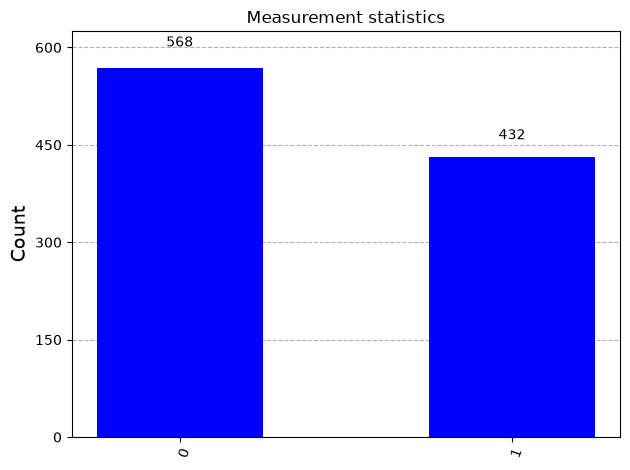

In [3]:
from qiskit.visualization import plot_histogram

statistics = v.sample_counts(shots=1000)
plot_histogram(statistics, title="Measurement statistics", color="blue")

Custom Unitaries

In [4]:
from qiskit.quantum_info import Operator

Y = Operator([[0, -1.0j], [1.0j, 0]])
H = Operator([[1 / sqrt(2), 1 / sqrt(2)], [1 / sqrt(2), -1 / sqrt(2)]])
S = Operator([[1, 0], [0, 1.0j]])
T = Operator([[1, 0], [0, (1 + 1.0j) / sqrt(2)]])

display(T.draw("latex"))

<IPython.core.display.Latex object>

In [5]:
v = Statevector([1, 0])

v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(S)
#v = v.evolve(Y)

display(v.draw("latex"))

<IPython.core.display.Latex object>

Quantum Circuits

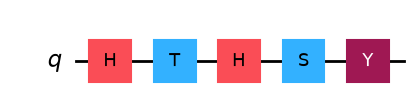

In [6]:
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.s(0)
circuit.y(0)

display(circuit.draw("mpl"))

In [7]:
print("Operation of the circuit: ")
display(Operator.from_circuit(circuit).draw("latex"))

Operation of the circuit: 


<IPython.core.display.Latex object>

We can also initialize a starting quantum state vector and then evolve that state according to the sequence of operations described by the circuit.

In [8]:
ket0 = Statevector([1, 0])
v = ket0.evolve(circuit)
display(v.draw("latex"))

<IPython.core.display.Latex object>